# 📈 Práctica guiada 
## Introducción a la Regresión Lineal 


**Objetivos**

1. Entender qué es un modelo de Machine Learning y qué es el aprendizaje supervisado.
2. Entender qué es una regresión lineal, para qué sirve y cuándo conviene usarla.
3. Crear, entrenar y usar un modelo de regresión lineal con la librería **Scikit-Learn**.
4. Dividir tus datos en entrenamiento y prueba, y saber por qué se hace.
5. Evaluar un modelo con las métricas **MAE, MSE, RMSE y R²** e interpretar los resultados.
6. Graficar datos y resultados con **Matplotlib** y **Seaborn**.
7. Reconocer ventajas, desventajas y limitaciones de la regresión lineal, y conocer otras variantes.

---


---
# 1. Conceptos previos: ¿qué es Machine Learning?

## 1.1 Machine Learning en una frase

**Machine Learning (aprendizaje automático)** es una forma de lograr que una computadora **aprenda patrones a partir de datos**, en lugar de programarle reglas a mano.

> **Ejemplo.** Si quisieras predecir el precio de una casa con programación clásica, tendrías que escribir las reglas vos mismo ("si tiene 100 m² cuesta tanto..."). Con Machine Learning, le mostrás a la computadora **miles de casas con sus precios reales** y ella **descubre sola** la relación entre las características y el precio.

A esa "relación descubierta" se la llama **modelo**.

## 1.2 Aprendizaje supervisado y no supervisado

| Tipo | ¿Qué le damos al algoritmo? | Ejemplo |
|---|---|---|
| **Supervisado** | Datos **con la respuesta correcta** (etiqueta) | Casas con su precio real → predecir el precio de una casa nueva |
| **No supervisado** | Datos **sin respuesta**; el algoritmo busca estructura por su cuenta | Agrupar clientes con hábitos de compra parecidos |

Esta práctica trabaja con **aprendizaje supervisado**.

## 1.3 Regresión y clasificación

Dentro del aprendizaje supervisado hay dos grandes familias, según lo que queremos predecir:

| Problema | ¿Qué predice? | Ejemplos |
|---|---|---|
| **Regresión** | Un **número continuo** | Precio de una casa, temperatura de mañana, ventas del mes |
| **Clasificación** | Una **categoría** | ¿El mail es spam o no? ¿El tumor es benigno o maligno? |

👉 **La regresión lineal es un algoritmo de *regresión***: sirve para predecir números.

## 1.4 Vocabulario básico (¡importante!)

Vamos a usar estas palabras todo el tiempo:

| Término | Significado | Ejemplo (precio de casas) |
|---|---|---|
| **Atributo / Característica / Feature** (`X`) | Datos de entrada que usamos para predecir | Superficie, antigüedad, cantidad de ambientes |
| **Etiqueta / Variable objetivo / Target** (`y`) | Lo que queremos predecir | El precio |
| **Registro / Instancia / Muestra** | Una fila del dataset | Una casa en particular |
| **Dataset** | El conjunto completo de datos | La tabla con todas las casas |
| **Entrenar** (`fit`) | Que el modelo aprenda a partir de los datos | Mostrarle casas con sus precios |
| **Predecir** (`predict`) | Usar el modelo ya entrenado sobre datos nuevos | Estimar el precio de una casa que no vio |

> **Convención:** se escribe `X` con **mayúscula** (puede tener varios atributos, es como una tabla) e `y` con **minúscula** (es una sola columna: la respuesta).

---
# 2. ¿Qué es la regresión lineal?

## 2.1 La idea

La **regresión lineal** busca la **recta** que mejor representa la relación entre una variable de entrada (`X`) y una variable de salida (`y`). Una vez que tenemos esa recta, podemos usarla para **predecir** valores nuevos.

Ecuación de una recta:

$$ y = m\,x + b $$

- **`m`** es la **pendiente**: cuánto cambia `y` cuando `x` aumenta en 1 unidad.
- **`b`** es la **ordenada al origen** (o *intercepto*): el valor de `y` cuando `x = 0`.

> **Ejemplo intuitivo.** Un taxi cobra $500 de bajada de bandera más $200 por kilómetro. El costo del viaje es `costo = 200 · km + 500`. Acá la pendiente es `m = 200` (cada km suma $200) y la ordenada es `b = 500` (lo que pagás aunque no te muevas).
>
> En Machine Learning pasa algo parecido, pero **no conocemos `m` y `b`**: el modelo los **aprende de los datos**.

## 2.2 El ruido: el mundo real no es perfecto

Si graficás datos reales, **nunca caen exactamente sobre una recta perfecta**. Hay variaciones por factores que no medimos, errores de medición, azar, etc. Para representar esto, agregamos un **término de error** (o *ruido*) a la ecuación:

$$ y = m\,x + b + \varepsilon $$

donde $\varepsilon$ (la letra griega *épsilon*) es un número aleatorio pequeño, distinto para cada dato. En esta práctica usaremos ruido con distribución normal, de media 0 y desvío 1: $\varepsilon \sim N(0, 1)$. Eso significa que casi siempre es un número chico (entre -2 y 2) y que los errores positivos y negativos se compensan en promedio.

## 2.3 ¿Para qué sirve?

La regresión lineal se usa para:

1. **Predecir**: estimar el precio de una vivienda, las ventas del próximo mes, la demanda de energía, etc.
2. **Entender relaciones**: ¿cuánto aumenta el precio por cada metro cuadrado adicional? La pendiente responde esa pregunta directamente.
3. **Tener una base de comparación (*baseline*)**: es el primer modelo que se prueba en muchos problemas; si un modelo más complejo no lo supera claramente, quizás no valga la pena la complejidad.

## 2.4 Regresión simple y múltiple

| Tipo | Atributos de entrada | Ecuación | Ejemplo |
|---|---|---|---|
| **Simple** | **1** | $y = m x + b$ | Precio según la superficie |
| **Múltiple** | **2 o más** | $y = m_1 x_1 + m_2 x_2 + \dots + b$ | Precio según superficie, antigüedad y ambientes |

En esta práctica vamos a ver **ambas**. Más adelante repasaremos otras variantes (polinómica, regularizada, etc.).

---
# 3. Preparación: las herramientas que vamos a usar

Para usar las librerias, hay que **importarlas** con la palabra `import`. Las que usaremos hoy:

| Librería | Alias habitual | ¿Para qué sirve? |
|---|---|---|
| **NumPy** | `np` | Trabajar con números y arreglos (listas de números) de forma rápida: generar datos, hacer cálculos matemáticos |
| **Pandas** | `pd` | Trabajar con **tablas** de datos (llamadas *DataFrames*), parecidas a una planilla de Excel |
| **Matplotlib** | `plt` | Crear **gráficos** (dispersión, líneas, histogramas, etc.) |
| **Seaborn** | `sns` | Gráficos estadísticos más vistosos, construidos sobre Matplotlib |
| **Scikit-Learn** | `sklearn` | La librería principal de Machine Learning: contiene modelos, métricas y herramientas para dividir datos |

El **alias** (`as np`) es un apodo corto para no tener que escribir el nombre completo cada vez. Por ejemplo, escribimos `np.mean(...)` en lugar de `numpy.mean(...)`.

> 💡 Si alguna librería no está instalada en tu computadora, descomentá  la primera línea de la celda siguiente y ejecutala. Si usás Google Colab, ya vienen instaladas.

In [1]:
# Si te falta alguna librería, quitá el "#" de la línea siguiente y ejecutá la celda:
# !pip install numpy pandas matplotlib seaborn scikit-learn

import numpy as np                 # cálculos numéricos
import pandas as pd                # tablas de datos
import matplotlib.pyplot as plt    # gráficos
import seaborn as sns              # gráficos estadísticos

# Esta línea hace que los gráficos se vean un poco más prolijos (grilla suave, fondo claro)
sns.set_theme(style="whitegrid")

print("¡Librerías importadas correctamente!")

¡Librerías importadas correctamente!


---
# 4. Regresión lineal simple (un solo atributo)

Vamos a trabajar con **datos sintéticos**, es decir, datos que **generamos nosotros con código**. ¿Por qué? Porque así **conocemos la respuesta correcta de antemano** y podemos verificar si el modelo logra descubrirla. En un problema real nunca sabés cuál es la "verdadera" relación.

## 4.1 Generar los datos

Vamos a crear 500 datos que siguen esta relación real:

$$ y = 3x - 2 + \varepsilon $$

Es decir, la pendiente verdadera es **m = 3** y la ordenada verdadera es **b = -2**. El modelo no lo sabe: tendrá que descubrirlo mirando los datos.

**Qué hace cada línea de la celda siguiente:**

- `np.random.seed(42)`: fija la "semilla" del generador aleatorio. Así, **todas las personas obtienen los mismos números "al azar"** y los resultados son reproducibles. (El 42 es solo una convención; podés usar otro número.)
- `n = 500`: cantidad de datos.
- `np.linspace(-2, 3, n)`: crea `n` números **equiespaciados** entre -2 y 3. Será nuestro atributo `X`.
- `y_real = 3 * X - 2`: la recta teórica, **sin ruido**.
- `np.random.randn(n)`: genera `n` números aleatorios con distribución normal (media 0, desvío 1). Es nuestro ruido $\varepsilon$.
- `y = y_real + ruido`: los datos "observados", como los que mediríamos en la realidad.

In [2]:
np.random.seed(42)   # semilla: hace que los números "aleatorios" sean siempre los mismos

n = 500                          # cantidad de datos
X = np.linspace(-2, 3, n)        # 500 valores equiespaciados entre -2 y 3
y_real = 3 * X - 2               # la recta teórica (sin ruido): m = 3, b = -2
ruido = np.random.randn(n)       # ruido aleatorio: media 0, desvío 1
y = y_real + ruido               # datos "observados" = recta + ruido

# Veamos los primeros 5 datos en forma de tabla (DataFrame de pandas)
tabla = pd.DataFrame({"X": X, "y_real (sin ruido)": y_real, "y (con ruido)": y})
tabla.head()

,X,y_real (sin ruido),y (con ruido)
0,-2.00000,-8.00000,-7.503286
1,-1.98998,-7.96994,-8.108204
2,-1.97996,-7.93988,-7.292191
3,-1.96994,-7.90982,-6.386790
4,-1.95992,-7.87976,-8.113913


Cada fila de la tabla es un **registro**. Observá que `y (con ruido)` es parecido a `y_real (sin ruido)`, pero no idéntico: esa diferencia es el ruido.

## 4.2 Graficar los datos

**Siempre conviene mirar los datos antes de modelar.** Un gráfico de **dispersión** (*scatter plot*) muestra cada dato como un punto.

**Qué hace cada línea:**

- `plt.figure(figsize=(12, 6))`: crea una figura nueva de 12 × 6 pulgadas (ancho × alto).
- `plt.scatter(X, y, ...)`: dibuja los puntos. `s=8` es el tamaño de cada punto y `alpha=0.6` su transparencia (0 = invisible, 1 = opaco).
- `plt.plot(X, y_real, '--', ...)`: dibuja una **línea**; `'--'` indica línea punteada y `c='red'` el color.
- `plt.xlabel / plt.ylabel / plt.title`: etiquetas de los ejes y título.
- `plt.legend()`: muestra la leyenda con los nombres definidos en `label=`.
- `plt.show()`: muestra el gráfico.

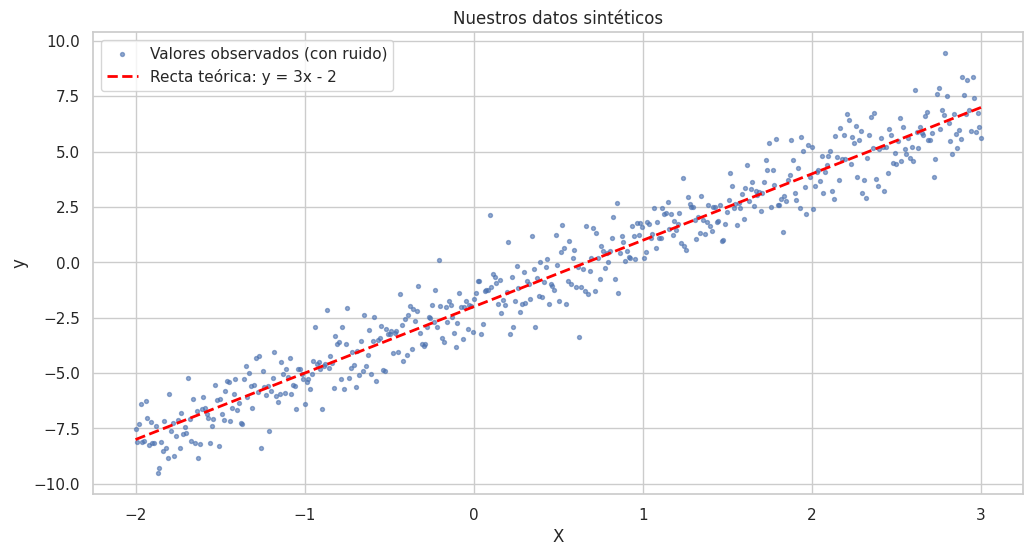

In [3]:
plt.figure(figsize=(12, 6))
plt.scatter(X, y, s=8, alpha=0.6, label="Valores observados (con ruido)")
plt.plot(X, y_real, "--", c="red", linewidth=2, label="Recta teórica: y = 3x - 2")
plt.xlabel("X")
plt.ylabel("y")
plt.title("Nuestros datos sintéticos")
plt.legend()
plt.show()

Los puntos forman una "nube" alargada alrededor de la recta roja. **Esa es la idea de una relación lineal con ruido.** La tarea del modelo es encontrar una recta lo más parecida posible a la roja, usando solamente los puntos azules.

## 4.3 ¿Cómo elige el modelo la "mejor" recta? 

Hay infinitas rectas posibles. ¿Cuál es la mejor? La que **se equivoca menos**. Para medirlo:

1. Para cada punto, calculamos la distancia vertical entre el valor real `y` y el valor que predice la recta $\hat{y}$ (se lee "y sombrero"). Esa diferencia es el **error** (o *residuo*): $e = y - \hat{y}$.
2. Elevamos cada error **al cuadrado** (para que los errores positivos y negativos no se cancelen, y para penalizar más los errores grandes).
3. Sumamos todo.

La recta que **minimiza esa suma** es la elegida. Este método se llama **mínimos cuadrados ordinarios** (en inglés, *OLS*, *Ordinary Least Squares*).

Veámoslo con un gráfico. Tomamos solo 15 puntos para que se vea claro y comparamos **dos rectas candidatas**: una mala y una buena. Las líneas punteadas grises son los errores.

> En la celda siguiente definimos la **función:  graficar_recta** 

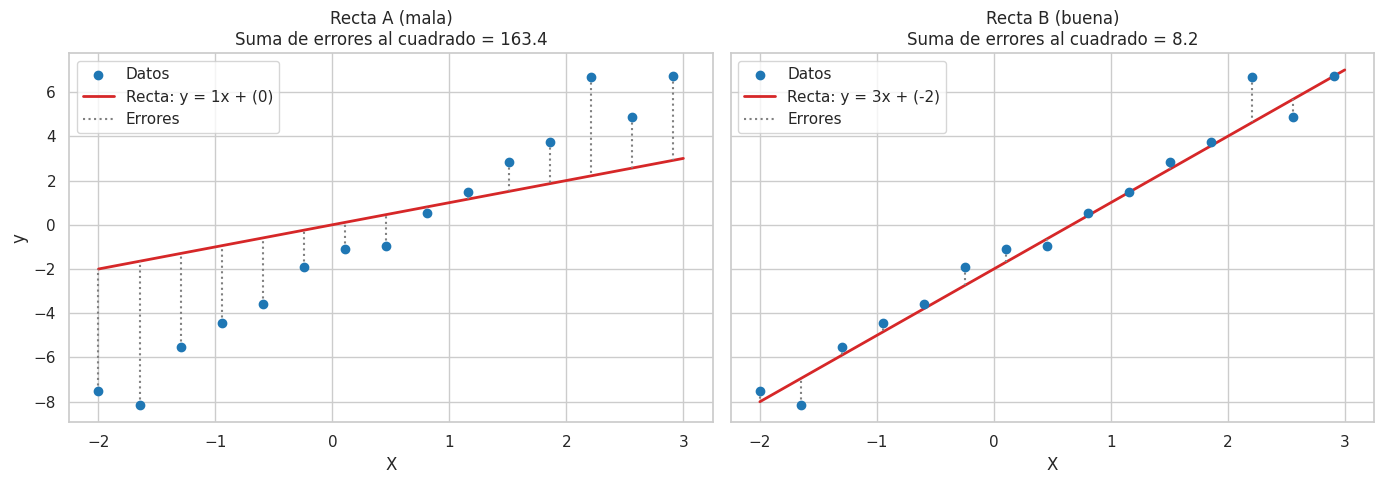

In [4]:
# Tomamos 15 puntos de nuestros 500 (uno cada 35) para que el gráfico sea legible
idx = np.arange(0, n, 35)
X_muestra, y_muestra = X[idx], y[idx]

def graficar_recta(ax, m, b, titulo):
    # Dibuja los puntos, una recta y = m*x + b, y los errores (líneas verticales)
    y_pred_muestra = m * X_muestra + b                       # lo que predice la recta
    ax.scatter(X_muestra, y_muestra, color="tab:blue", zorder=3, label="Datos")
    extremos = np.array([X.min(), X.max()])                  # para dibujar la recta de punta a punta
    ax.plot(extremos, m * extremos + b, color="tab:red", linewidth=2, label=f"Recta: y = {m}x + ({b})")
    ax.vlines(X_muestra, y_muestra, y_pred_muestra, color="gray", linestyle=":", label="Errores")
    suma_cuadrados = np.sum((y_muestra - y_pred_muestra) ** 2)   # suma de errores al cuadrado
    ax.set_title(f"{titulo}\nSuma de errores al cuadrado = {suma_cuadrados:.1f}")
    ax.set_xlabel("X")
    ax.legend()

# Creamos una figura con 2 gráficos lado a lado (1 fila, 2 columnas)
fig, ejes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
graficar_recta(ejes[0], m=1, b=0, titulo="Recta A (mala)")
graficar_recta(ejes[1], m=3, b=-2, titulo="Recta B (buena)")
ejes[0].set_ylabel("y")
plt.tight_layout()
plt.show()

La recta B tiene errores mucho más chicos, por lo tanto una suma de cuadrados mucho menor. **El algoritmo de regresión lineal prueba (matemáticamente, de forma directa) cuál es la recta con la menor suma posible** y nos la entrega.

## 4.4 Calcular la recta "a mano" con la fórmula

Para el caso de un solo atributo, los valores óptimos de la pendiente `m` y la ordenada `b` tienen una **fórmula cerrada** (se obtiene con cálculo diferencial; no hace falta que la deduzcas):

$$ m = \frac{n \sum x_i y_i - \sum x_i \sum y_i}{n \sum x_i^2 - \left(\sum x_i\right)^2} \qquad\qquad b = \frac{\sum y_i - m \sum x_i}{n} $$

El símbolo $\sum$ (sigma) significa **"sumar todos los valores"**. Por ejemplo, $\sum x_i$ es la suma de todos los `X`.

En NumPy, con un arreglo `X` podemos hacer `X.sum()` para sumarlo y `X**2` para elevar al cuadrado **cada elemento** a la vez.

In [ ]:
# Pendiente (m) según la fórmula
m_manual = (n * (X * y).sum() - X.sum() * y.sum()) / (n * (X ** 2).sum() - X.sum() ** 2)

# Ordenada al origen (b) según la fórmula
b_manual = (y.sum() - m_manual * X.sum()) / n

print("Pendiente calculada a mano:           ", round(m_manual, 4), "  (valor real: 3)")
print("Ordenada al origen calculada a mano:  ", round(b_manual, 4), "  (valor real: -2)")

Los valores obtenidos son **muy cercanos** a los verdaderos (3 y -2), aunque no exactos: el ruido hace que nunca los recuperemos a la perfección. Con más datos o menos ruido, la aproximación mejoraría.

## 4.5 Lo mismo, pero con Scikit-Learn

Calcular a mano está bien para entender, pero con muchos atributos sería inviable. Para eso usamos **Scikit-Learn**, que ya trae el algoritmo implementado.

### El flujo de trabajo en Scikit-Learn

Casi todos los modelos de Scikit-Learn se usan **siguiendo los mismos tres pasos**:

| Paso | Qué hacemos | Código típico |
|---|---|---|
| **1. Instanciar** | Crear el modelo (todavía "vacío", no sabe nada) | `modelo = LinearRegression()` |
| **2. Entrenar** | Mostrarle los datos para que aprenda | `modelo.fit(X, y)` |
| **3. Predecir** | Pedirle respuestas para datos nuevos | `modelo.predict(X_nuevo)` |

> En términos de programación: `LinearRegression` es una **clase** (un molde); `modelo` es un **objeto** creado a partir de ese molde; y `fit` y `predict` son **métodos** (acciones) que el objeto sabe hacer.

### Un detalle técnico importante: la forma de `X`

Scikit-Learn espera que `X` sea una **tabla de dos dimensiones**: *filas = registros, columnas = atributos*. Nuestro `X` actual es un arreglo de una sola dimensión (una lista de 500 números), así que hay que **darle forma de tabla de 500 filas × 1 columna**. Eso hace `X.reshape(-1, 1)`: el `1` es la cantidad de columnas y el `-1` significa "calculá vos cuántas filas hacen falta".

In [ ]:
from sklearn.linear_model import LinearRegression   # importamos la clase del modelo

print("Forma original de X:   ", X.shape)            # (500,)  -> una dimensión
X_2d = X.reshape(-1, 1)                              # lo convertimos a tabla: 500 filas x 1 columna
print("Forma de X para sklearn:", X_2d.shape)        # (500, 1) -> dos dimensiones

# Paso 1: instanciar el modelo
modelo_prueba = LinearRegression()

# Paso 2: entrenar (el modelo calcula la pendiente y la ordenada)
modelo_prueba.fit(X_2d, y)

# Los valores aprendidos se guardan en atributos que terminan con "_"
print("\nPendiente aprendida (coef_):             ", modelo_prueba.coef_[0])
print("Ordenada al origen aprendida (intercept_):", modelo_prueba.intercept_)

Los resultados de Scikit-Learn **coinciden con los que calculamos a mano** (comparalos con la celda anterior). Es la misma matemática, solo que ya resuelta por la librería.

> **Nota sobre los nombres:** en Scikit-Learn, todo lo que el modelo "aprende" durante `fit` termina con un guion bajo: `coef_` (las pendientes) e `intercept_` (la ordenada). Por eso `coef_` es un arreglo: en regresión múltiple tendrá **una pendiente por cada atributo**.

## 4.6 Dividir los datos: entrenamiento y prueba (*train / test split*)

Hasta ahora entrenamos con **todos** los datos. Pero así no podemos saber si el modelo **funciona con datos que nunca vio**, que es lo que realmente importa.

> **Analogía del examen.** Si un estudiante practica con 10 ejercicios y el examen tiene **exactamente esos mismos 10**, una buena nota no prueba que haya aprendido: tal vez los memorizó. Para saber si realmente aprendió, el examen debe tener **ejercicios nuevos**.

Con los modelos pasa igual. Por eso **separamos los datos en dos grupos**:

- **Conjunto de entrenamiento (*train*)**, típicamente 70-80 %: el modelo aprende con él (ve `X` **y** la `y` correcta).
- **Conjunto de prueba (*test*)**, típicamente 20-30 %: lo "escondemos" durante el entrenamiento. Después le pedimos al modelo que prediga `y` solo a partir de `X`, y **comparamos sus predicciones con la `y` real** para medir qué tan bien generaliza.

Usamos la función `train_test_split`:

- `test_size=0.30`: el 30 % de los datos será para prueba.
- `random_state=42`: fija la semilla del sorteo para que la división sea siempre la misma (reproducibilidad).
- Por defecto, la función **mezcla los datos al azar** antes de dividir.
- Devuelve **cuatro cosas**, en este orden: `X_train, X_test, y_train, y_test`.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_2d, y,
    test_size=0.30,      # 30% para prueba
    random_state=42      # para que el sorteo sea reproducible
)

print("Datos de entrenamiento:", X_train.shape, y_train.shape)   # 350 registros
print("Datos de prueba:       ", X_test.shape, y_test.shape)     # 150 registros

De los 500 datos, **350 se usarán para entrenar** y **150 para evaluar**.

>**Regla importante:** el conjunto de prueba **nunca** se usa para entrenar. Si lo hiciéramos, la evaluación sería "tramposa" y no sabríamos cómo se comportará el modelo en el mundo real.

>**Excepción importante:** cuando los datos son una **serie de tiempo** (por ejemplo, ventas mes a mes), no se mezclan al azar: se entrena con el pasado y se prueba con el futuro, porque en la realidad nunca vas a tener datos del futuro para entrenar.

## 4.7 Entrenar el modelo y hacer predicciones

Ahora sí, aplicamos los tres pasos del flujo de trabajo, **entrenando solo con el conjunto de entrenamiento**:

In [ ]:
# Paso 1: instanciar el modelo
modelo = LinearRegression()

# Paso 2: entrenar usando SOLO los datos de entrenamiento
modelo.fit(X_train, y_train)

# Paso 3: predecir. Pedimos predicciones para ambos conjuntos
y_train_pred = modelo.predict(X_train)   # predicciones sobre datos que el modelo YA vio
y_test_pred = modelo.predict(X_test)     # predicciones sobre datos que el modelo NO vio

print("Pendiente aprendida:            ", round(modelo.coef_[0], 4), "  (real: 3)")
print("Ordenada al origen aprendida:   ", round(modelo.intercept_, 4), "  (real: -2)")
print(f"\nEcuación del modelo: y = {modelo.coef_[0]:.3f} * x + ({modelo.intercept_:.3f})")

### ¿Y si quiero predecir un valor nuevo?

Con el modelo entrenado, predecir es muy simple: le pasamos un valor de `X` (con la forma de tabla de 2 dimensiones) y nos devuelve la `y` estimada. Por ejemplo, ¿qué predice el modelo si `x = 2`? Según la recta real, el valor sin ruido sería `3·2 - 2 = 4`.

In [ ]:
x_nuevo = np.array([[2]])             # un solo dato nuevo; los dobles corchetes dan forma de tabla (1 fila, 1 columna)
prediccion = modelo.predict(x_nuevo)

print("Para x = 2, el modelo predice y =", round(prediccion[0], 3), "(valor teórico sin ruido: 4)")

## 4.8 Visualizar el modelo

Grafiquemos todo junto. Mostramos los datos de entrenamiento y de prueba con colores distintos, la recta teórica (roja punteada) y la recta aprendida por el modelo (verde).

Para dibujar la recta del modelo usamos `modelo.predict(X_2d)`: predice `y` para cada `X` y los une con una línea.

In [ ]:
plt.figure(figsize=(12, 6))
plt.scatter(X_train, y_train, s=8, alpha=0.5, label="Entrenamiento (350)")
plt.scatter(X_test, y_test, s=8, alpha=0.7, color="orange", label="Prueba (150)")
plt.plot(X, y_real, "--", c="red", linewidth=2, label="Recta teórica")
plt.plot(X, modelo.predict(X_2d), c="green", linewidth=2, label="Recta aprendida por el modelo")
plt.xlabel("X")
plt.ylabel("y")
plt.title("Regresión lineal simple: modelo vs. realidad")
plt.legend()
plt.show()

La recta verde (aprendida) está **casi encima** de la roja (teórica). El modelo logró descubrir la relación a partir de datos ruidosos. 

Pero "se ve bien" **no es una medida objetiva**. Necesitamos números que cuantifiquen qué tan bien predice. De eso se trata la siguiente sección.

---
# 5. Evaluación del modelo

**Evaluar un modelo es medir la calidad de sus predicciones.** Siempre se hace comparando lo que el modelo predijo ($\hat{y}$) con lo que realmente ocurrió ($y$), idealmente sobre el **conjunto de prueba**.

## 5.1 El error

Para cada registro, el **error** es:

$$ e_i = y_i - \hat{y}_i $$

- Si el valor real es 5 y el modelo predijo 6, el error es **-1** (sobreestimó).
- Si el valor real es 5 y el modelo predijo 4, el error es **+1** (subestimó).

La idea natural sería promediar todos los errores. **Pero hay un problema:** los errores positivos y negativos se cancelan. Un modelo que se equivoca +100 en la mitad de los casos y -100 en la otra mitad tendría un error promedio de 0... aunque sea un mal modelo!

Por eso se usan **métricas** que evitan esa cancelación, ya sea con valor absoluto o elevando al cuadrado. Veamos las más usadas.

## 5.2 Métricas de error: MAE, MSE y RMSE

### MAE: Error Absoluto Medio (*Mean Absolute Error*)

$$ MAE = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i| $$

Promedia los errores **sin signo** (valor absoluto).

- ✅ **Fácil de interpretar:** está en las **mismas unidades** que `y`. Un MAE de 2 significa "en promedio me equivoco por 2 unidades".
- ✅ Es **robusto a valores atípicos** (outliers): un error enorme pesa lo mismo que su tamaño, no más.
- ❌ Trata igual a todos los errores: no castiga especialmente los errores muy grandes.

### MSE: Error Cuadrático Medio (*Mean Squared Error*)

$$ MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 $$

Promedia los errores **elevados al cuadrado**.

- ✅ **Castiga mucho más los errores grandes** (un error de 10 pesa 100 veces más que uno de 1). Útil cuando los errores grandes son particularmente costosos.
- ✅ Es la función que el modelo de regresión lineal **minimiza** al entrenarse.
- ❌ Sus **unidades están al cuadrado** (si `y` son metros, el MSE son metros²), lo que dificulta la interpretación.
- ❌ **Muy sensible a outliers.**

### RMSE: Raíz del Error Cuadrático Medio (*Root Mean Squared Error*)

$$ RMSE = \sqrt{MSE} $$

Es la raíz cuadrada del MSE, lo que **devuelve el error a las unidades originales** de `y`.

- ✅ Interpretable como el MAE y, a la vez, castiga los errores grandes.
- ❌ También es sensible a outliers (aunque menos que el MSE).

> **Regla práctica:** el RMSE siempre es **mayor o igual** que el MAE. Si son muy distintos, es señal de que hay unos pocos errores muy grandes.

**Para las tres métricas: cuanto más bajo, mejor.** Un valor de 0 sería un modelo perfecto.

## 5.3 R²: Coeficiente de determinación

$$ R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2} $$

donde $\bar{y}$ es el **promedio** de los valores reales.

**¿Qué mide?** Compara tu modelo contra un modelo deficiente que **siempre predice el promedio** de `y`. Responde: *¿qué proporción de la variabilidad de `y` logra explicar mi modelo?*

| Valor de R² | Interpretación |
|---|---|
| **1** | El modelo explica el 100 % de la variabilidad (perfecto) |
| **0,9** | Explica el 90 % (muy bueno) |
| **0** | No es mejor que predecir siempre el promedio |
| **< 0** | **Peor** que predecir siempre el promedio (modelo muy malo) |

- ✅ **No depende de las unidades**, así que sirve para comparar modelos en distintos problemas.
- ❌ **Por sí solo no alcanza:** un R² alto no garantiza que el modelo sea adecuado (por ejemplo, si el modelo está mal planteado o hay sobreajuste). Conviene mirarlo junto con el RMSE/MAE y con gráficos.

## 5.4 Calcular las métricas

Primero las calculamos **a mano con NumPy** (para entender qué hacen) y luego con **Scikit-Learn** (que es lo que se usa en la práctica). Deberían dar lo mismo.

**Qué hace cada línea:**
- `errores = y_test - y_test_pred`: el error de cada registro del conjunto de prueba.
- `np.abs(...)`: valor absoluto.
- `np.mean(...)`: promedio.
- `np.sqrt(...)`: raíz cuadrada.

In [ ]:
# --- Cálculo manual sobre el conjunto de PRUEBA ---
errores = y_test - y_test_pred                    # error de cada registro

mae_manual  = np.mean(np.abs(errores))            # promedio de |error|
mse_manual  = np.mean(errores ** 2)               # promedio de error^2
rmse_manual = np.sqrt(mse_manual)                 # raíz del MSE

# R^2: 1 - (suma de errores^2) / (variación total respecto del promedio)
suma_errores_cuad = np.sum(errores ** 2)
variacion_total   = np.sum((y_test - np.mean(y_test)) ** 2)
r2_manual = 1 - suma_errores_cuad / variacion_total

print("--- Cálculo manual (conjunto de prueba) ---")
print(f"MAE : {mae_manual:.4f}")
print(f"MSE : {mse_manual:.4f}")
print(f"RMSE: {rmse_manual:.4f}")
print(f"R²  : {r2_manual:.4f}")

In [ ]:
# --- Cálculo con Scikit-Learn (lo que se usa en la práctica) ---
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae  = mean_absolute_error(y_test, y_test_pred)
mse  = mean_squared_error(y_test, y_test_pred)
rmse = np.sqrt(mse)                                # sklearn devuelve el MSE; la raíz la hacemos con NumPy
r2   = r2_score(y_test, y_test_pred)

print("--- Cálculo con Scikit-Learn (conjunto de prueba) ---")
print(f"MAE : {mae:.4f}")
print(f"MSE : {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²  : {r2:.4f}")

### ¿Cómo interpretamos estos números?

- **RMSE ≈ 1:** el ruido que agregamos tenía desvío 1, o sea que **ese es el error mínimo que se puede esperar**: ningún modelo puede predecir el ruido, porque es aleatorio. Un RMSE cercano a 1 significa que nuestro modelo **captó casi todo lo que había para captar**.
- **R² alto (cercano a 0,96):** el modelo explica la gran mayoría de la variabilidad de `y`. No llega a 1 justamente por el ruido.
- **RMSE depende de las unidades.** Un RMSE de 1 es "bueno" o "malo" según la escala de `y`. Acá `y` varía entre -8 y 7 aprox., así que un error de 1 es razonable. Para saber si un RMSE es bueno, **siempre comparalo con el rango o el promedio de `y`**.

## 5.5 Comparar entrenamiento vs. prueba

Una buena práctica es calcular las métricas **en ambos conjuntos** y compararlas:

- Si train y test dan **resultados parecidos** → el modelo **generaliza** bien. 
- Si train es **mucho mejor** que test → el modelo **memorizó** los datos de entrenamiento (*sobreajuste* u *overfitting*) y falla con datos nuevos. 
- Si **ambos son malos** → el modelo es demasiado simple para el problema (*subajuste* o *underfitting*). 

Para no repetir el mismo código, armamos una **función** que calcula las 4 métricas y devuelve un diccionario.

In [ ]:
def calcular_metricas(y_verdadero, y_predicho):
    # Recibe los valores reales y los predichos, y devuelve un diccionario con las 4 métricas
    mse = mean_squared_error(y_verdadero, y_predicho)
    return {
        "MAE": mean_absolute_error(y_verdadero, y_predicho),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R²": r2_score(y_verdadero, y_predicho),
    }

# Armamos una tablita comparativa con pandas: una fila por conjunto
comparacion = pd.DataFrame({
    "Entrenamiento": calcular_metricas(y_train, y_train_pred),
    "Prueba": calcular_metricas(y_test, y_test_pred),
}).T                                   # .T "da vuelta" la tabla (transpone filas y columnas)

comparacion.round(4)

Los valores de entrenamiento y prueba son **muy parecidos**: el modelo generaliza bien y no hay señales de sobreajuste.

## 5.6 Gráficos para evaluar

Los números resumen, pero **los gráficos muestran cosas que los números esconden**. Hacemos dos:

**Gráfico 1 — Histograma de errores.** Muestra cuántos errores hay de cada tamaño. En un buen modelo lineal, los errores deberían:
- estar **centrados en 0** (no se equivoca sistemáticamente para un lado),
- tener forma de **campana** (distribución normal),
- ser parecidos en train y test.

**Gráfico 2 — Valor real vs. valor predicho.** Cada punto compara la `y` real (eje horizontal) con la predicha (eje vertical). Si el modelo fuera perfecto, todos los puntos caerían **sobre la diagonal**. Cuanto más cerca de la diagonal, mejor.

*Detalles de código:* `plt.subplot(1, 2, 1)` crea una grilla de 1 fila × 2 columnas y selecciona el primer gráfico. `sns.histplot` dibuja el histograma (`bins` = cantidad de barras, `kde=True` agrega la curva suavizada) y `stat="density"` hace que el eje vertical sea comparable entre conjuntos de distinto tamaño.

In [ ]:
plt.figure(figsize=(14, 5))

# --- Gráfico 1: histograma de errores ---
plt.subplot(1, 2, 1)
sns.histplot(y_train - y_train_pred, bins=20, kde=True, stat="density", color="tab:red",  alpha=0.4, label="Entrenamiento")
sns.histplot(y_test  - y_test_pred,  bins=20, kde=True, stat="density", color="tab:blue", alpha=0.4, label="Prueba")
plt.axvline(0, color="black", linestyle="--")      # línea vertical en error = 0
plt.title("Histograma de errores")
plt.xlabel("Error (y real - y predicho)")
plt.ylabel("Densidad")
plt.legend()

# --- Gráfico 2: real vs. predicho ---
plt.subplot(1, 2, 2)
plt.scatter(y_test, y_test_pred, s=10, alpha=0.7, label="Datos de prueba")
limites = [min(y_test.min(), y_test_pred.min()), max(y_test.max(), y_test_pred.max())]
plt.plot(limites, limites, "k--", label="Predicción perfecta (diagonal)")
plt.title("Y real vs. Y predicho (prueba)")
plt.xlabel("y real")
plt.ylabel("y predicho")
plt.legend()

plt.tight_layout()
plt.show()

**Cómo leer estos gráficos:**

- En el histograma, los errores se agrupan en forma de campana **alrededor de 0**, tanto en entrenamiento como en prueba. 
- En el gráfico de real vs. predicho, los puntos siguen la diagonal. Se dispersan un poco a su alrededor, y esa dispersión es exactamente el ruido que no se puede predecir.

>**Si vieras otra cosa**, sería una pista de que algo no anda bien: errores con forma de curva (el modelo no captó una relación no lineal), errores que crecen a medida que crece `y` (la varianza no es constante), o muchos puntos muy lejos de la diagonal (outliers). Más adelante vemos ejemplos.

---
# 6. Regresión lineal múltiple (dos o más atributos)

En la vida real, casi nunca una sola variable alcanza para predecir algo. El precio de una casa depende de la superficie, **y también** de la antigüedad, la zona, la cantidad de ambientes... La **regresión lineal múltiple** permite usar **varios atributos a la vez**:

$$ y = m_1 x_1 + m_2 x_2 + \dots + m_k x_k + b + \varepsilon $$

Hay **una pendiente por cada atributo** (también llamadas *coeficientes*) y una sola ordenada al origen.

- Con **1 atributo** el modelo es una **recta** (2 dimensiones).
- Con **2 atributos** es un **plano** o superficie (3 dimensiones: `x₁`, `x₂` e `y`).
- Con **3 o más atributos** es un *hiperplano*: no se puede dibujar, pero la matemática funciona igual.

## 6.1 Generar datos con dos atributos

Creamos 500 datos con esta relación real:

$$ y = -3x_1 + 2x_2 + 4 + \varepsilon $$

Los valores reales son: `m₁ = -3`, `m₂ = 2`, `b = 4`.

- `np.random.rand(n)`: genera `n` números aleatorios **uniformes entre 0 y 1**.
- `np.vstack((x1, x2)).T`: apila `x1` y `x2` como dos filas y luego las **transpone** para obtener una tabla con **500 filas y 2 columnas** (una columna por atributo), que es el formato que pide Scikit-Learn.

In [ ]:
np.random.seed(7)

n = 500
x1 = np.random.rand(n)                                # primer atributo (entre 0 y 1)
x2 = np.random.rand(n)                                # segundo atributo (entre 0 y 1)
y = -3 * x1 + 2 * x2 + 4 + np.random.randn(n)         # relación real + ruido

X = np.vstack((x1, x2)).T                             # tabla de 500 filas x 2 columnas
print("Forma de X:", X.shape)
print("Forma de y:", y.shape)

## 6.2 Visualizar los datos en 3D

Con dos atributos y la variable de salida necesitamos **tres ejes**. Usamos un gráfico de dispersión 3D. No es necesario que entiendas cada detalle del código: lo importante es ver que los puntos forman una "nube" que tiene la forma de un **plano inclinado** con ruido.

*(Detalle de código: `projection="3d"` le indica a Matplotlib que cree ejes tridimensionales. `view_init` ajusta el ángulo de la cámara; podés cambiar esos números para rotar la vista.)*

In [ ]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(x1, x2, y, s=8, alpha=0.6)
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("y")
ax.set_title("Datos con dos atributos")
ax.view_init(elev=20, azim=-60)       # ángulo de vista: elevación y rotación
plt.show()

## 6.3 Dividir, entrenar y predecir

Los pasos son **exactamente los mismos** que en la regresión simple. Solo cambia que `X` ahora tiene **2 columnas**. Esa es una de las grandes ventajas de Scikit-Learn: el flujo es siempre igual.

In [ ]:
# 1) Dividir en entrenamiento (70%) y prueba (30%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)
print("Entrenamiento:", X_train.shape, y_train.shape)
print("Prueba:       ", X_test.shape, y_test.shape)

# 2) Instanciar y entrenar
modelo_multiple = LinearRegression()
modelo_multiple.fit(X_train, y_train)

# 3) Predecir
y_train_pred = modelo_multiple.predict(X_train)
y_test_pred = modelo_multiple.predict(X_test)

# Ahora coef_ tiene DOS valores: uno por cada atributo
print("\nPendientes aprendidas (m1, m2):", modelo_multiple.coef_.round(3), "  (reales: -3 y 2)")
print("Ordenada al origen aprendida:  ", round(modelo_multiple.intercept_, 3), "  (real: 4)")

### ¿Cómo se interpretan los coeficientes?

En una regresión múltiple, cada coeficiente se interpreta **manteniendo constantes los demás atributos**:

- **`m₁ ≈ -3`**: si `x₁` aumenta en 1 unidad **y `x₂` no cambia**, `y` **disminuye** en promedio unas 3 unidades (signo negativo = relación inversa).
- **`m₂ ≈ 2`**: si `x₂` aumenta en 1 unidad **y `x₁` no cambia**, `y` **aumenta** en promedio unas 2 unidades (signo positivo = relación directa).

Esa capacidad de **interpretar** el modelo es una de las grandes virtudes de la regresión lineal.

## 6.4 Visualizar el plano de regresión

Con dos atributos, el modelo ya no es una recta sino un **plano**. Para dibujarlo, armamos una grilla de puntos (`np.meshgrid`), le pedimos al modelo que prediga `y` en cada uno y dibujamos la superficie resultante con `plot_surface`.

In [ ]:
# Armamos una grilla de 30 x 30 puntos que cubra el rango [0, 1] de ambos atributos
valores = np.linspace(0, 1, 30)
G1, G2 = np.meshgrid(valores, valores)                          # todas las combinaciones (x1, x2)
grilla = np.column_stack([G1.ravel(), G2.ravel()])              # lo convertimos en tabla de 900 filas x 2 columnas
Z = modelo_multiple.predict(grilla).reshape(G1.shape)           # predicciones, con la forma de la grilla

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(x1, x2, y, s=8, alpha=0.5, label="Datos")
ax.plot_surface(G1, G2, Z, cmap="coolwarm", alpha=0.5)          # el plano que aprendió el modelo
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("y")
ax.set_title("Plano de regresión aprendido por el modelo")
ax.view_init(elev=20, azim=-60)
plt.show()

El plano atraviesa la nube de puntos por el medio, igual que la recta lo hacía en 2D.

## 6.5 Evaluar el modelo múltiple

Reutilizamos la función `calcular_metricas` que definimos antes, ¡para eso sirven las funciones!

In [ ]:
comparacion_multiple = pd.DataFrame({
    "Entrenamiento": calcular_metricas(y_train, y_train_pred),
    "Prueba": calcular_metricas(y_test, y_test_pred),
}).T

comparacion_multiple.round(4)

Fijate que el **R² es bastante menor** que en el ejemplo simple (alrededor de 0,55 en lugar de 0,96), pero **el RMSE sigue siendo cercano a 1**, o sea, **igual de bueno**. ¿Por qué cambió el R²?

Porque en este caso `y` varía **menos** (los atributos están entre 0 y 1, así que `y` se mueve poco), mientras que el **ruido sigue siendo el mismo (desvío 1)**. Entonces el ruido representa una porción más grande de la variabilidad total y el R² baja, aunque el modelo haya hecho su trabajo igual de bien.

> **Importante:** un R² bajo **no siempre** significa un modelo malo. Dependerá de cuánto ruido haya en los datos. Por eso conviene mirar varias métricas y los gráficos.

## 6.6 Un ejemplo más realista: precio de casas

Pasemos de números abstractos a algo con significado. Generamos un dataset ficticio de **300 casas** con tres columnas: superficie (m²), antigüedad (años) y precio (USD). Los precios se calculan con esta regla "oculta" (que el modelo no conoce) más algo de ruido:

$$ precio = 1500 \cdot superficie - 800 \cdot antiguedad + 20000 + \varepsilon $$

Acá usamos un **DataFrame de pandas**, que es el formato más común en proyectos reales: cada columna tiene nombre, lo que hace el código más legible. Observá cómo seleccionamos columnas con `casas[["superficie_m2", "antiguedad_anios"]]` (doble corchete = varias columnas).

In [ ]:
np.random.seed(0)
n_casas = 300

casas = pd.DataFrame({
    "superficie_m2": np.random.uniform(30, 200, n_casas),     # entre 30 y 200 m²
    "antiguedad_anios": np.random.uniform(0, 50, n_casas),    # entre 0 y 50 años
})
# El precio sigue la regla oculta + ruido (desvío de 10.000 USD)
casas["precio_usd"] = (1500 * casas["superficie_m2"]
                       - 800 * casas["antiguedad_anios"]
                       + 20000
                       + np.random.normal(0, 10000, n_casas))

casas.head()       # primeras 5 filas

In [ ]:
# Separamos atributos (X) y etiqueta (y)
X_casas = casas[["superficie_m2", "antiguedad_anios"]]
y_casas = casas["precio_usd"]

# Dividimos, entrenamos
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_casas, y_casas, test_size=0.25, random_state=42)
modelo_casas = LinearRegression().fit(Xc_train, yc_train)     # instanciar y entrenar en un solo paso

# Mostramos los coeficientes con el nombre de cada atributo
coeficientes = pd.Series(modelo_casas.coef_, index=X_casas.columns)
print("Coeficientes aprendidos:")
print(coeficientes.round(1))
print(f"\nOrdenada al origen: {modelo_casas.intercept_:.0f}   (real: 20000)")

# Evaluamos en prueba
metricas_casas = calcular_metricas(yc_test, modelo_casas.predict(Xc_test))
print(f"\nRMSE en prueba: {metricas_casas['RMSE']:.0f} USD")
print(f"R² en prueba:   {metricas_casas['R²']:.3f}")

**Interpretación en lenguaje de negocio:**

- Cada metro cuadrado adicional suma **unos 1.500 USD** al precio (coeficiente de `superficie_m2`).
- Cada año de antigüedad **resta unos 800 USD** (coeficiente negativo de `antiguedad_anios`).
- El **RMSE ronda los 10.000 USD**: en promedio, nos equivocamos por esa cantidad. Como los precios van de unos 20.000 a más de 300.000 USD, es un error razonable. (¡Y coincide con el ruido que pusimos!)

Ahora usemos el modelo para **predecir el precio de una casa nueva**: una de 80 m² con 10 años de antigüedad. Le pasamos un DataFrame con las mismas columnas que usamos para entrenar.

In [ ]:
casa_nueva = pd.DataFrame({"superficie_m2": [80], "antiguedad_anios": [10]})
precio_estimado = modelo_casas.predict(casa_nueva)[0]

print(f"Precio estimado: {precio_estimado:,.0f} USD")
print(f"Precio según la regla oculta (sin ruido): {1500*80 - 800*10 + 20000:,.0f} USD")

---
# 7. Tipos de regresión y alternativas

Ya conocés dos variantes: la **simple** y la **múltiple**. Hay otras que conviene conocer de nombre y saber cuándo se usan.

| Variante | ¿Qué hace? | ¿Cuándo se usa? | Clase en Scikit-Learn |
|---|---|---|---|
| **Lineal simple** | Una recta con 1 atributo | Relación lineal entre dos variables | `LinearRegression` |
| **Lineal múltiple** | Un plano/hiperplano con varios atributos | Cuando varios factores influyen en el resultado | `LinearRegression` |
| **Polinómica** | Ajusta **curvas** (agrega potencias: x², x³...) | Cuando la relación **no es una línea recta** pero sigue una curva suave | `PolynomialFeatures` + `LinearRegression` |
| **Ridge (L2)** | Regresión lineal que **penaliza coeficientes grandes** | Muchos atributos, atributos correlacionados entre sí, o para reducir el sobreajuste | `Ridge` |
| **Lasso (L1)** | Como Ridge, pero puede **llevar coeficientes exactamente a 0** | Para **seleccionar atributos** automáticamente (descarta los poco útiles) | `Lasso` |
| **Elastic Net** | Combina Ridge y Lasso | Cuando querés un punto intermedio entre ambos | `ElasticNet` |

> **No confundir con la regresión logística.** A pesar de su nombre, la regresión logística **no predice números sino categorías** (es un algoritmo de *clasificación*). La veremos en la próxima práctica.

En las próximas dos celdas vemos en acción **dos situaciones** donde la regresión lineal simple tiene problemas: relaciones **curvas** y **valores atípicos**.

## 7.1 Cuando la relación no es una recta: regresión polinómica

Generamos datos que siguen una **parábola** ($y = x^2$) con ruido y probamos ajustarlos con una recta y con un polinomio de grado 2.

**Detalles de código:**
- `PolynomialFeatures(degree=2)` crea automáticamente un atributo extra con $x^2$. Así, el modelo sigue siendo **lineal en los coeficientes**, pero puede dibujar una curva.
- `make_pipeline(...)` encadena pasos en un solo modelo: primero transforma `X` y luego aplica la regresión.

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

np.random.seed(1)
x_curva = np.linspace(-3, 3, 200)
y_curva = x_curva ** 2 + np.random.randn(200) * 0.8       # parábola con ruido
x_curva_2d = x_curva.reshape(-1, 1)

# Modelo 1: regresión lineal común (una recta)
modelo_recta = LinearRegression().fit(x_curva_2d, y_curva)

# Modelo 2: regresión polinómica de grado 2 (una parábola)
modelo_parabola = make_pipeline(PolynomialFeatures(degree=2), LinearRegression()).fit(x_curva_2d, y_curva)

print(f"R² de la recta:    {r2_score(y_curva, modelo_recta.predict(x_curva_2d)):.3f}")
print(f"R² de la parábola: {r2_score(y_curva, modelo_parabola.predict(x_curva_2d)):.3f}")

plt.figure(figsize=(12, 6))
plt.scatter(x_curva, y_curva, s=10, alpha=0.6, label="Datos")
plt.plot(x_curva, modelo_recta.predict(x_curva_2d), color="red", linewidth=2, label="Regresión lineal (recta)")
plt.plot(x_curva, modelo_parabola.predict(x_curva_2d), color="green", linewidth=2, label="Regresión polinómica (grado 2)")
plt.title("Cuando la relación es curva, una recta no alcanza")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()

La recta roja **ignora por completo la forma de U** (R² cercano a 0: no mejora nada respecto de predecir el promedio), mientras que la parábola verde se ajusta muy bien. **Moraleja:** antes de usar regresión lineal, **graficá tus datos** para ver si una recta tiene sentido.

>**Cuidado con los grados altos.** Un polinomio de grado muy alto puede "perseguir" cada punto, incluido el ruido, y caer en **sobreajuste**. Empezá con grados bajos (2 o 3) y comprobá siempre con el conjunto de prueba.

## 7.2 Sensibilidad a valores atípicos (*outliers*)

Un **outlier** es un dato que se aleja mucho del resto (por un error de carga, un caso excepcional, etc.). Como la regresión lineal minimiza errores **al cuadrado**, un solo dato muy alejado puede "tirar" de la recta. Lo comprobamos: ajustamos el mismo conjunto de datos con y sin 5 valores atípicos.

In [ ]:
np.random.seed(3)
x_o = np.linspace(0, 10, 50)
y_o = 2 * x_o + 1 + np.random.randn(50)          # datos limpios: y = 2x + 1 + ruido

# Copia de los datos, pero con los últimos 5 valores "corrompidos" (les restamos 25)
y_o_atipicos = y_o.copy()
y_o_atipicos[-5:] = y_o_atipicos[-5:] - 25

x_o_2d = x_o.reshape(-1, 1)
modelo_limpio = LinearRegression().fit(x_o_2d, y_o)
modelo_con_atipicos = LinearRegression().fit(x_o_2d, y_o_atipicos)

print(f"Pendiente con datos limpios:    {modelo_limpio.coef_[0]:.2f}  (real: 2)")
print(f"Pendiente con 5 outliers:       {modelo_con_atipicos.coef_[0]:.2f}")

plt.figure(figsize=(12, 6))
plt.scatter(x_o[:-5], y_o_atipicos[:-5], color="tab:blue", label="Datos normales")
plt.scatter(x_o[-5:], y_o_atipicos[-5:], color="red", marker="x", s=80, label="Outliers")
plt.plot(x_o, modelo_limpio.predict(x_o_2d), color="green", linewidth=2, label="Recta sin outliers")
plt.plot(x_o, modelo_con_atipicos.predict(x_o_2d), color="orange", linewidth=2, label="Recta con outliers")
plt.title("Los outliers arrastran la recta")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()

Solo 5 datos de 50 (un 10 %) lograron **cambiar notablemente la pendiente** de la recta (la recta naranja es mucho más plana que la verde). Por eso, en la práctica, hay que **detectar y analizar los outliers** antes de modelar (con gráficos, por ejemplo) y decidir si corresponde corregirlos, eliminarlos o usar modelos más robustos.

---
# 8. Ventajas, desventajas y cuándo usar regresión lineal

## 8.1 Ventajas 

| Ventaja | Explicación |
|---|---|
| **Simple y rápida** | Se entrena en una fracción de segundo, incluso con muchos datos |
| **Interpretable** | Cada coeficiente dice cuánto cambia `y` al cambiar un atributo: se puede explicar a personas no técnicas |
| **Pocos datos necesarios** | Funciona razonablemente bien con datasets chicos |
| **Buen punto de partida (*baseline*)** | Sirve de referencia para comparar modelos más complejos |
| **Sin hiperparámetros que ajustar** (en su versión básica) | No hay que "afinar" configuraciones complicadas |
| **Base teórica sólida** | Es una técnica estudiada hace más de 200 años, con mucha teoría y herramientas disponibles |

## 8.2 Desventajas 

| Desventaja | Explicación |
|---|---|
| **Asume una relación lineal** | Si la relación real es curva o compleja, el modelo se equivoca sistemáticamente (vimos el ejemplo de la parábola) |
| **Sensible a outliers** | Pocos datos extremos pueden distorsionar el resultado (lo vimos en 7.2) |
| **Atributos correlacionados** | Si dos atributos miden casi lo mismo (*multicolinealidad*), los coeficientes se vuelven inestables y difíciles de interpretar |
| **No captura interacciones complejas** | No detecta por sí sola efectos del tipo "A influye solo cuando B es alto" |
| **Solo predice números** | No sirve directamente para categorías (para eso existe la clasificación) |
| **Puede predecir valores imposibles** | Por ejemplo, un precio negativo o una probabilidad mayor a 100 %, porque la recta no tiene límites |
| **Extrapolar es riesgoso** | Fuera del rango de datos de entrenamiento, la predicción puede no tener sentido |

## 8.3 Supuestos de la regresión lineal

Para que los resultados sean confiables (sobre todo si querés interpretar coeficientes), se espera que se cumplan estas condiciones:

1. **Linealidad:** la relación entre `X` e `y` es aproximadamente una recta.
2. **Independencia:** los errores de un dato no dependen de los de otro. (Se viola en series de tiempo, donde un dato depende del anterior.)
3. **Varianza constante (homocedasticidad):** la dispersión de los errores es similar en todo el rango de `X`.
4. **Errores con distribución normal:** los errores forman una campana centrada en 0 (como vimos en el histograma).
5. **Sin multicolinealidad fuerte:** los atributos no deberían estar casi duplicados entre sí.

> No hace falta que se cumplan a la perfección. Son una guía: cuanto más se violen, menos confiable será el modelo.

## 8.4 ¿Cuándo conviene usarla?

| Usala cuando... | Considerá otra alternativa cuando... |
|---|---|
| Querés **predecir un número** (precio, ventas, temperatura, consumo) | Querés predecir una **categoría** → usá clasificación (p. ej. regresión logística) |
| El gráfico de dispersión muestra una **tendencia aproximadamente recta** | La relación es claramente **curva** → probá regresión polinómica o modelos no lineales |
| Necesitás **explicar** el modelo a otras personas | Solo te importa la precisión y no la explicación → podrías probar modelos más complejos (árboles, *random forest*, redes neuronales) |
| Tenés **pocos datos** | Tenés muchísimos atributos correlacionados → Ridge, Lasso o Elastic Net |
| Querés un modelo **rápido** como punto de partida | Hay muchos **outliers** que no podés limpiar → modelos robustos |

**Ejemplos de uso real:** estimar el precio de propiedades, predecir la demanda de un producto según el precio y la publicidad, estimar el consumo eléctrico según la temperatura, analizar cómo influye el nivel de estudios en el ingreso, proyectar tendencias de ventas.

---
# 9. Ejercicios para practicar 

Cada ejercicio tiene una **pista**. Escribí tu código en las celdas vacías (donde dice `# Tu código acá`).

---
### Ejercicio 1: primer modelo desde cero

Generá 300 datos que sigan la relación $y = -5x + 10 + \varepsilon$, con $x$ entre 0 y 10 y ruido con **desvío 2** (usá `np.random.randn(300) * 2`). Luego:

1. Dividí en entrenamiento y prueba (80 % / 20 %).
2. Entrená un modelo de regresión lineal.
3. Mostrá la pendiente y la ordenada aprendidas. ¿Se parecen a -5 y 10?
4. Calculá el RMSE y el R² en el conjunto de prueba.

> **Pista:** repetír los pasos de la sección 4. Recordar usar `.reshape(-1, 1)` en `X`. El RMSE esperado es cercano al desvío del ruido (≈ 2).

In [ ]:
# Tu código acá

---
### Ejercicio 2: ¿cuánto importa el tamaño del conjunto de prueba?

Volvé a generar los datos de la sección 4.1 (las variables `X` e `y` fueron reemplazadas en la sección 6, así que hay que crearlas de nuevo) y probá `test_size` de **0.1**, **0.3** y **0.5**. Para cada uno, entrená el modelo y anotá el RMSE y el R² en prueba.

¿Cambian mucho los resultados? ¿Por qué creés que pasa?

> **Pista:** hacer un bucle `for tamaño in [0.1, 0.3, 0.5]:` y dentro repetí `train_test_split`, `fit`, `predict` y las métricas. Con pocos datos de prueba, la métrica es menos estable.

In [ ]:
# Tu código acá

---
### Ejercicio 3: el efecto del ruido

Con la relación $y = 3x - 2 + \varepsilon$ (x entre -2 y 3, 500 datos), generá tres datasets con ruido de desvío **0.5**, **2** y **5**. Entrená un modelo con cada uno y comparalos:

- ¿Cómo cambian el R² y el RMSE al aumentar el ruido?
- ¿Se sigue aproximando el modelo a la pendiente real (3)?
- Graficá los tres casos.

> **Pista:** en `np.random.randn(500) * desvio` el número `desvio` controla cuánto ruido hay. Más ruido → los puntos se dispersan más → el R² baja, aunque la pendiente aprendida suela seguir siendo parecida.

In [ ]:
# Tu código acá

---
### Ejercicio 4 (desafío): predecir con un modelo múltiple

Agregá a la tabla `casas` (sección 6.6) una nueva columna `ambientes` con valores enteros entre 1 y 5 (`np.random.randint(1, 6, n_casas)`). Modificá el precio para que **cada ambiente sume 5000 USD**. Reentrená el modelo con **tres atributos** y verificá si el coeficiente de `ambientes` se parece a 5000.

> **Pista:** el flujo es idéntico, solo cambia la lista de columnas de `X` y la fórmula del precio.

In [ ]:
# Tu código acá

---
# 10. Resumen y glosario

## 10.1 Lo aprendido

1. **Machine Learning supervisado:** el modelo aprende de datos que incluyen la respuesta correcta. Si la respuesta es un **número**, es un problema de **regresión**.
2. **Regresión lineal:** busca la recta (o plano) que mejor se ajusta a los datos, minimizando la suma de los errores al cuadrado. Ecuación: $y = mx + b$.
3. **Flujo en Scikit-Learn:** `instanciar → fit (entrenar) → predict (predecir)`.
4. **Train/test split:** separamos datos para entrenar y para evaluar, y así comprobar que el modelo funciona con datos nuevos.
5. **Métricas:** MAE, MSE y RMSE miden el error (más bajo = mejor); R² mide la proporción de variabilidad explicada (más cerca de 1 = mejor).
6. **Regresión múltiple:** usa varios atributos; cada coeficiente se interpreta manteniendo constantes los demás.
7. **Limitaciones:** supone relaciones lineales, es sensible a outliers y no extrapola bien. Hay variantes (polinómica, Ridge, Lasso) para algunos de estos problemas.

## 10.2 Código esencial para recordar

```python
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

modelo = LinearRegression()           # 1. instanciar
modelo.fit(X_train, y_train)          # 2. entrenar
y_pred = modelo.predict(X_test)       # 3. predecir

rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)
```

## 10.3 Glosario

| Término | Definición |
|---|---|
| **Atributo (feature)** | Variable de entrada usada para predecir (`X`) |
| **Etiqueta (target)** | Variable que se quiere predecir (`y`) |
| **Coeficiente / pendiente** | Cuánto cambia `y` al aumentar 1 unidad un atributo |
| **Ordenada al origen (intercepto)** | Valor de `y` cuando todos los atributos valen 0 |
| **Residuo / error** | Diferencia entre el valor real y el predicho |
| **Ruido** | Variación aleatoria que ningún modelo puede predecir |
| **Entrenar (`fit`)** | Proceso por el cual el modelo aprende de los datos |
| **Generalizar** | Funcionar bien con datos que no vio durante el entrenamiento |
| **Sobreajuste (overfitting)** | El modelo memoriza el entrenamiento y falla con datos nuevos |
| **Subajuste (underfitting)** | El modelo es demasiado simple y falla incluso en el entrenamiento |
| **Outlier** | Dato muy alejado del resto |
| **Mínimos cuadrados** | Método que elige la recta que minimiza la suma de errores al cuadrado |
| **DataFrame** | Tabla de datos de Pandas, con filas y columnas con nombre |

## 10.4 Próximo paso:

- Aplicar lo aprendido a **datos reales**: Kaggle y el repositorio UCI Machine Learning tienen datasets gratuitos para practicar.
- Explorar la [documentación de Scikit-Learn](https://scikit-learn.org/stable/modules/linear_model.html), que tiene una sección completa sobre modelos lineales.

